In [14]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("train.csv")

print("Shape of dataset:", df.shape)
display(df.head())
print("\nDataset Info:")
df.info()

missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100
missing_df = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_pct.round(2)
})
missing_df = missing_df[missing_df["Missing_Count"] > 0].sort_values(
    by="Missing_Count", ascending=False
)

print(f"\nColumns with missing values: {len(missing_df)}")
display(missing_df)

Shape of dataset: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64 

,Missing_Count,Missing_Percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


In [15]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for col, order in ordinal_map.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

summary_rows = []
for col in df.columns:
    if col in ordinal_map or col == "OverallQual":
        var_type = "Ordinal"
    elif col in numeric_cols:
        var_type = "Numerical"
    else:
        var_type = "Categorical"

    examples = df[col].dropna().unique()[:3].tolist()
    summary_rows.append({
        "Column": col,
        "Type": var_type,
        "Unique_Values": df[col].nunique(),
        "Example_Values": examples
    })

var_summary = pd.DataFrame(summary_rows)
display(var_summary.head(20))

,Column,Type,Unique_Values,Example_Values
0,Id,Numerical,1460,"[1, 2, 3]"
1,MSSubClass,Numerical,15,"[60, 20, 70]"
2,MSZoning,Categorical,5,"[RL, RM, C (all)]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250]"
5,Street,Categorical,2,"[Pave, Grvl]"
6,Alley,Categorical,2,"[Grvl, Pave]"
7,LotShape,Categorical,4,"[Reg, IR1, IR2]"
8,LandContour,Categorical,4,"[Lvl, Bnk, Low]"
9,Utilities,Categorical,2,"[AllPub, NoSeWa]"


In [ ]:
display(df.describe().T)


for col in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[col].dropna()
    mean_val = s.mean()
    median_val = s.median()
    mode_val = s.mode()[0]
    std_val = s.std()
    var_val = s.var()
    range_val = s.max() - s.min()
    iqr_val = s.quantile(0.75) - s.quantile(0.25)
    skew_val = s.skew()
    kurt_val = s.kurt()

    skew_dir = "right skewed" if mean_val > median_val else ("left skewed" if mean_val < median_val else "symmetric")

    print(f"\n--- {col} ---")
    print(f"Mean: {mean_val:,.2f} | Median: {median_val:,.2f} | Mode: {mode_val:,.2f}")
    print(f"Std: {std_val:,.2f} | Variance: {var_val:,.2f}")
    print(f"Range: {range_val:,.2f} | IQR: {iqr_val:,.2f}")
    print(f"Skewness: {skew_val:.3f} ({skew_dir}) | Kurtosis: {kurt_val:.3f}")


for col in ["Neighborhood", "HouseStyle"]:
    print(f"\n--- {col} (Mode: {df[col].mode()[0]}) ---")
    display(df[col].value_counts())


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0



--- SalePrice ---
Mean: 180,921.20 | Median: 163,000.00 | Mode: 140,000.00
Std: 79,442.50 | Variance: 6,311,111,264.30
Range: 720,100.00 | IQR: 84,025.00
Skewness: 1.883 (right skewed) | Kurtosis: 6.536

--- GrLivArea ---
Mean: 1,515.46 | Median: 1,464.00 | Mode: 864.00
Std: 525.48 | Variance: 276,129.63
Range: 5,308.00 | IQR: 647.25
Skewness: 1.367 (right skewed) | Kurtosis: 4.895

--- LotArea ---
Mean: 10,516.83 | Median: 9,478.50 | Mode: 7,200.00
Std: 9,981.26 | Variance: 99,625,649.65
Range: 213,945.00 | IQR: 4,048.00
Skewness: 12.208 (right skewed) | Kurtosis: 203.243

--- Neighborhood (Mode: NAmes) ---


,count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73



--- HouseStyle (Mode: 1Story) ---


,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


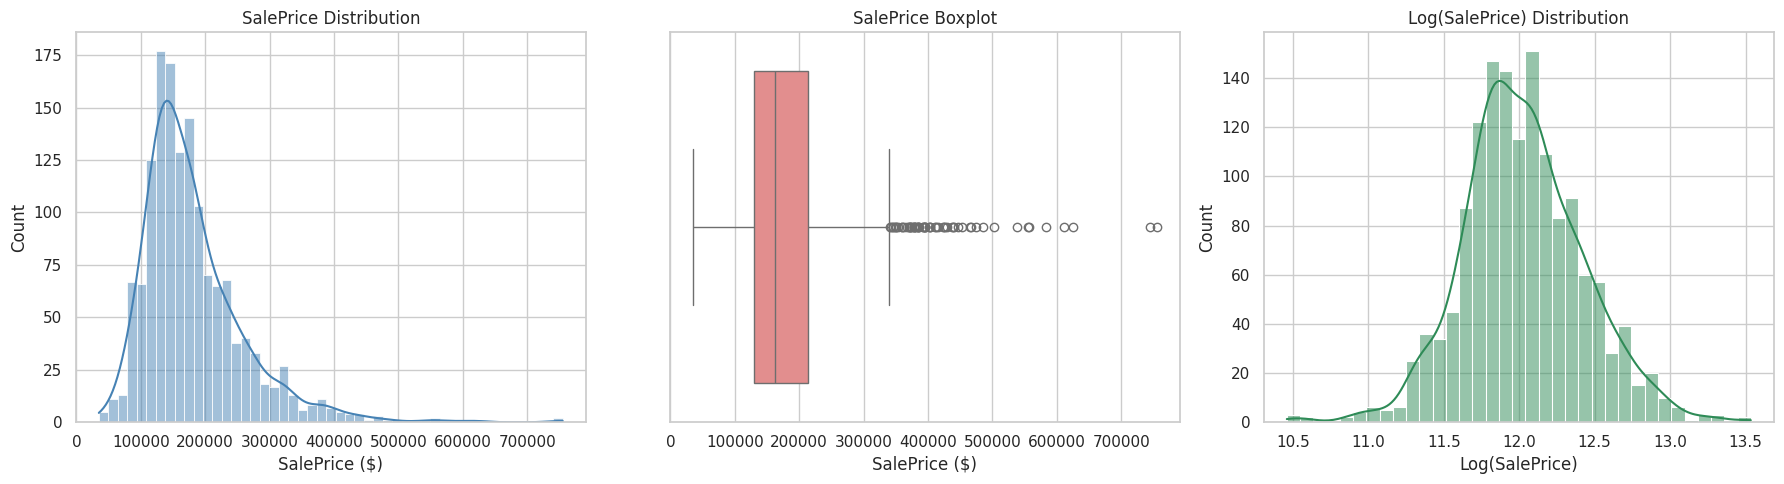

Skewness before log: 1.883
Skewness after log:  0.121


/tmp/ipykernel_808/1632502036.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="OverallQual", y="SalePrice", palette="viridis")


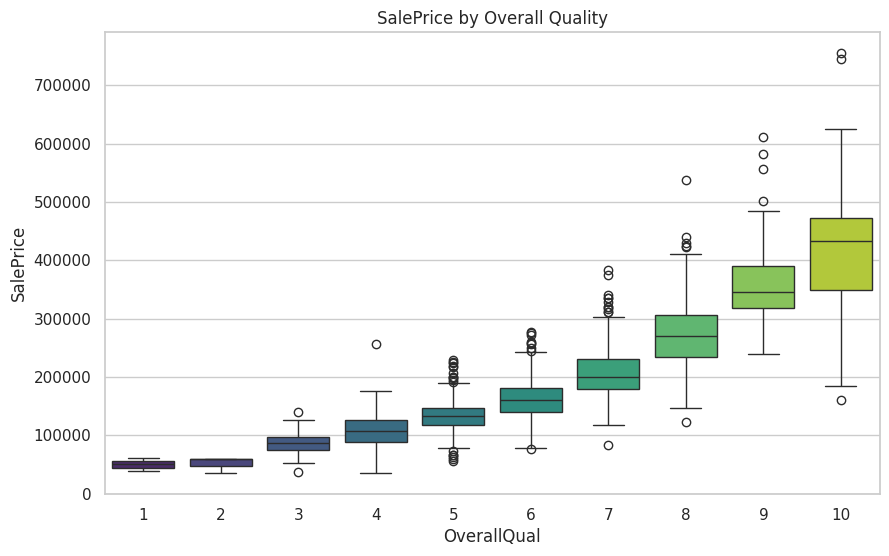

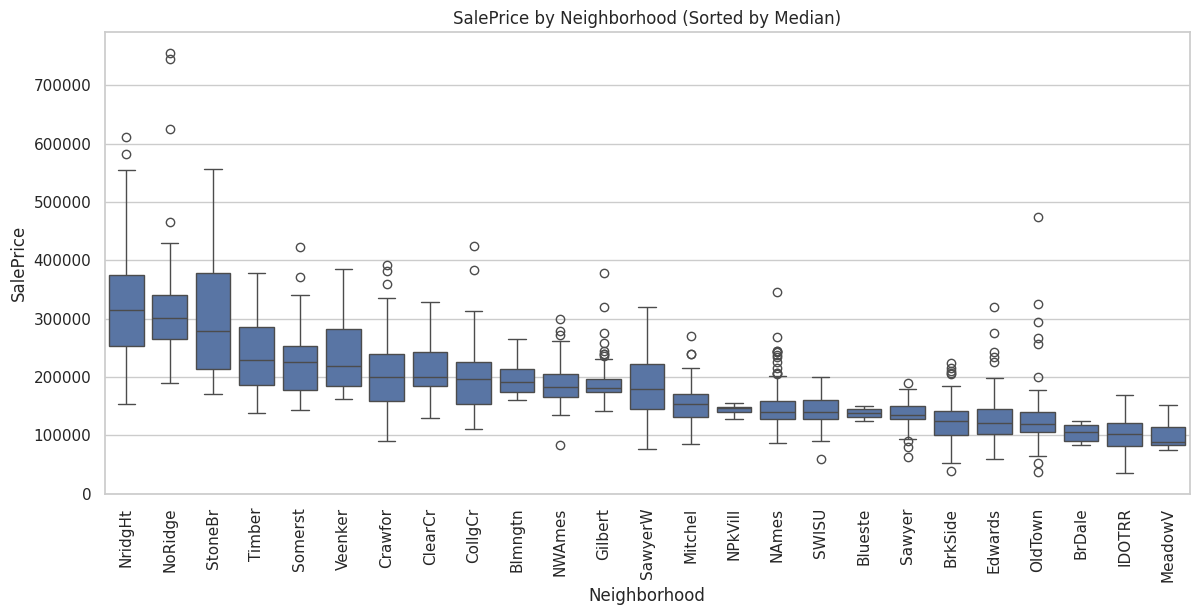

/tmp/ipykernel_808/1632502036.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="OverallQual", ax=axes[0], palette="Blues_d")
/tmp/ipykernel_808/1632502036.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="HouseStyle", ax=axes[1], order=df["HouseStyle"].value_counts().index, palette="Set2")


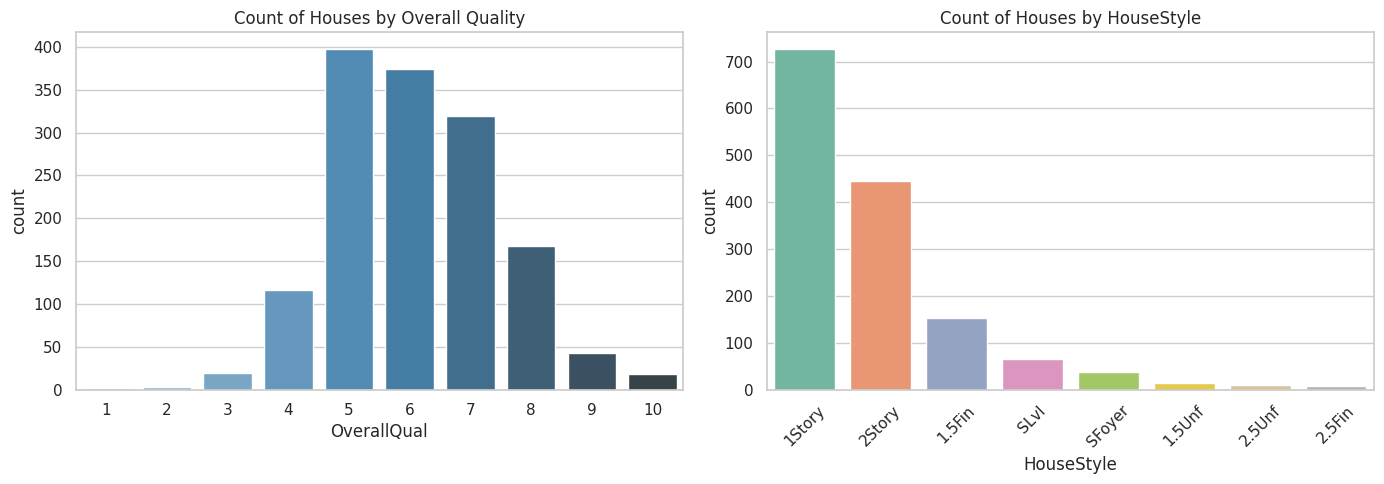

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("SalePrice ($)")
axes[0].set_ylabel("Count")

sns.boxplot(x=df["SalePrice"], ax=axes[1], color="lightcoral")
axes[1].set_title("SalePrice Boxplot")
axes[1].set_xlabel("SalePrice ($)")

log_price = np.log(df["SalePrice"])
sns.histplot(log_price, kde=True, ax=axes[2], color="seagreen")
axes[2].set_title("Log(SalePrice) Distribution")
axes[2].set_xlabel("Log(SalePrice)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Skewness before log: {df['SalePrice'].skew():.3f}")
print(f"Skewness after log:  {log_price.skew():.3f}")


plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", palette="viridis")
plt.title("SalePrice by Overall Quality")
plt.show()

order = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).index
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=order)
plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood (Sorted by Median)")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="OverallQual", ax=axes[0], palette="Blues_d")
axes[0].set_title("Count of Houses by Overall Quality")

sns.countplot(data=df, x="HouseStyle", ax=axes[1], order=df["HouseStyle"].value_counts().index, palette="Set2")
axes[1].set_title("Count of Houses by HouseStyle")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [16]:
num_df = df.select_dtypes(include=[np.number])

cov_matrix = num_df.cov()
corr_matrix = num_df.corr(method="pearson")

top_corr = corr_matrix["SalePrice"].abs().sort_values(ascending=False)
top_10_features = top_corr.index[1:11]

print("Top 10 Features Correlated with SalePrice (Pearson):")
print(corr_matrix.loc[top_10_features, "SalePrice"].round(3))

print("\nCovariance vs Correlation for Top 3 Features:")
for feat in top_10_features[:3]:
    cov_val = cov_matrix.loc[feat, "SalePrice"]
    corr_val = corr_matrix.loc[feat, "SalePrice"]
    print(f"{feat:15s} | Covariance: {cov_val:12,.2f} | Correlation: {corr_val:.3f}")

ordinal_df = pd.DataFrame({
    "SalePrice": df["SalePrice"],
    "OverallQual": df["OverallQual"],
    "ExterQual": df["ExterQual"].cat.codes,
    "KitchenQual": df["KitchenQual"].cat.codes
})
print("\nSpearman Correlation with SalePrice (Ordinal Features):")
print(ordinal_df.corr(method="spearman")["SalePrice"].round(3))

Top 10 Features Correlated with SalePrice (Pearson):
OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64

Covariance vs Correlation for Top 3 Features:
OverallQual     | Covariance:    86,904.13 | Correlation: 0.791
GrLivArea       | Covariance: 29,581,866.74 | Correlation: 0.709
GarageCars      | Covariance:    38,020.18 | Correlation: 0.640

Spearman Correlation with SalePrice (Ordinal Features):
SalePrice      1.000
OverallQual    0.810
ExterQual      0.684
KitchenQual    0.673
Name: SalePrice, dtype: float64


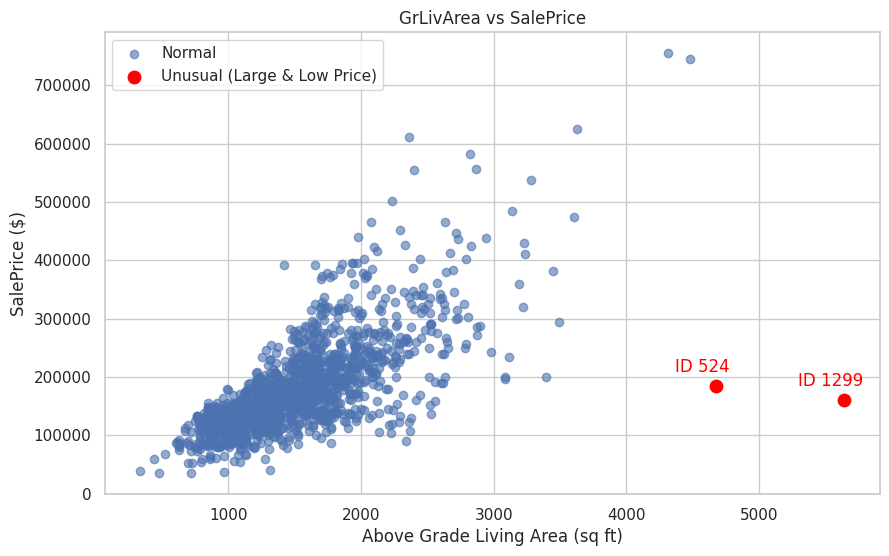

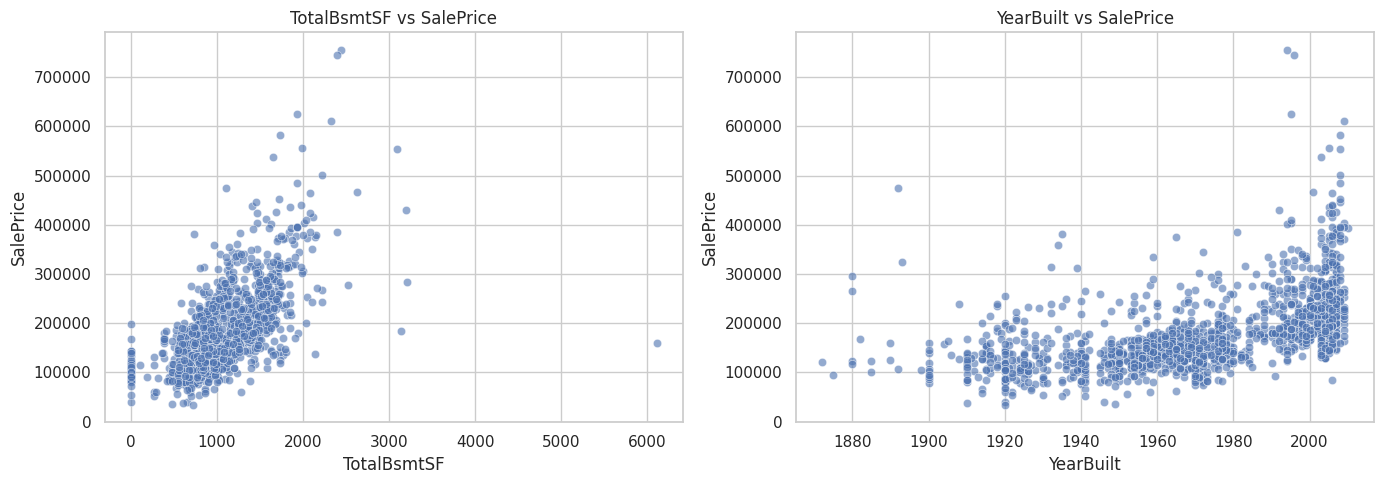

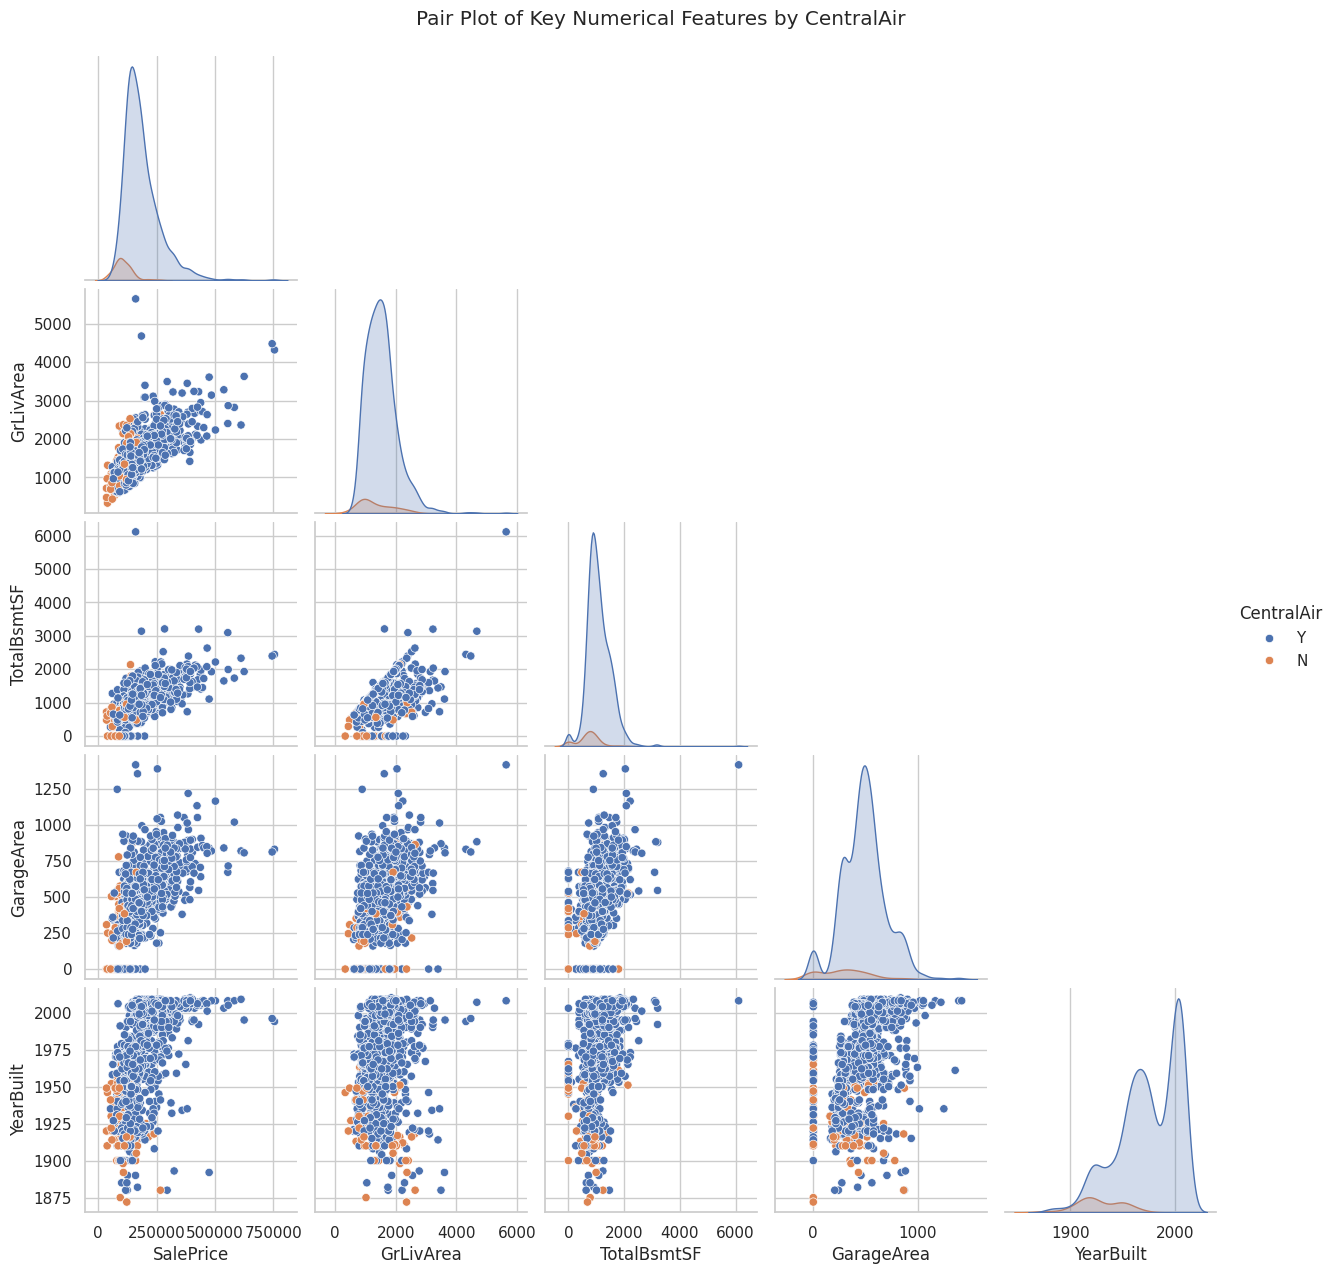

In [17]:
plt.figure(figsize=(10, 6))
anomalies = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
normal = df.drop(anomalies.index)

plt.scatter(normal["GrLivArea"], normal["SalePrice"], alpha=0.6, label="Normal")
plt.scatter(anomalies["GrLivArea"], anomalies["SalePrice"], color="red", s=80, label="Unusual (Large & Low Price)")

for idx, row in anomalies.iterrows():
    plt.annotate(f"ID {row['Id']}", (row["GrLivArea"], row["SalePrice"]),
                 textcoords="offset points", xytext=(-10, 10), ha="center", color="red")

plt.title("GrLivArea vs SalePrice")
plt.xlabel("Above Grade Living Area (sq ft)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice", alpha=0.6, ax=axes[0])
axes[0].set_title("TotalBsmtSF vs SalePrice")

sns.scatterplot(data=df, x="YearBuilt", y="SalePrice", alpha=0.6, ax=axes[1])
axes[1].set_title("YearBuilt vs SalePrice")

plt.tight_layout()
plt.show()

selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt", "CentralAir"]
sns.pairplot(df[selected], hue="CentralAir", diag_kind="kde", corner=True)
plt.suptitle("Pair Plot of Key Numerical Features by CentralAir", y=1.02)
plt.show()

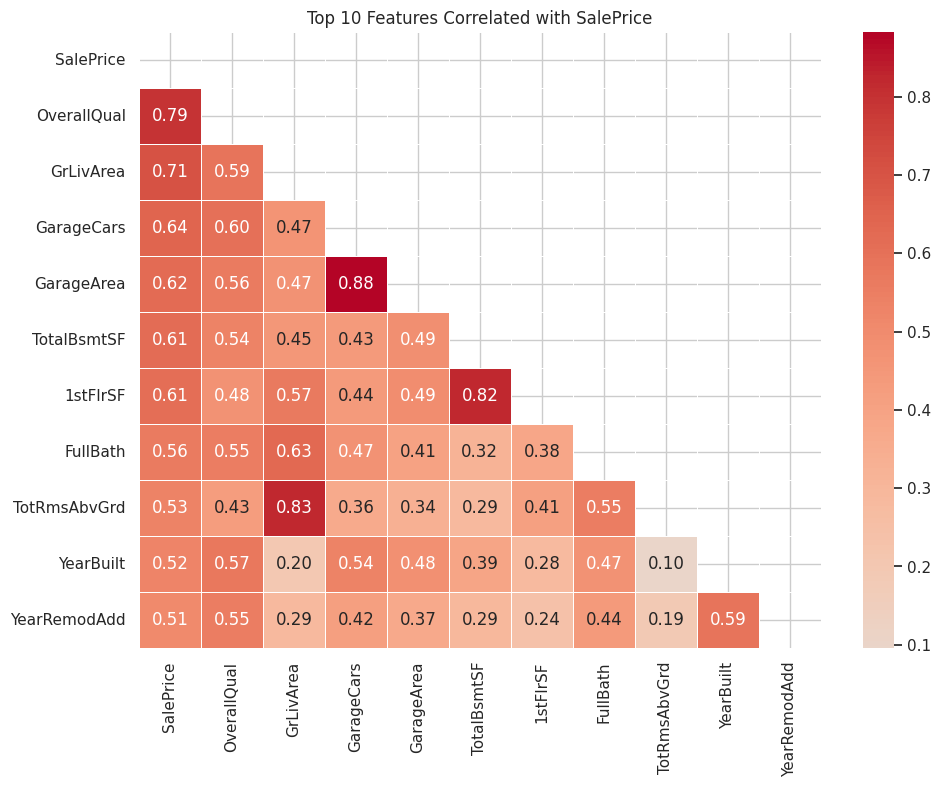

In [18]:
top10_cols = corr_matrix["SalePrice"].abs().sort_values(ascending=False).index[:11]
corr_top = df[top10_cols].corr()

mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr_top,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Top 10 Features Correlated with SalePrice")
plt.show()

--- GrLivArea ---
IQR outliers: 31 | Z-score outliers: 16 | Overlap: 16
--- SalePrice ---
IQR outliers: 61 | Z-score outliers: 22 | Overlap: 22


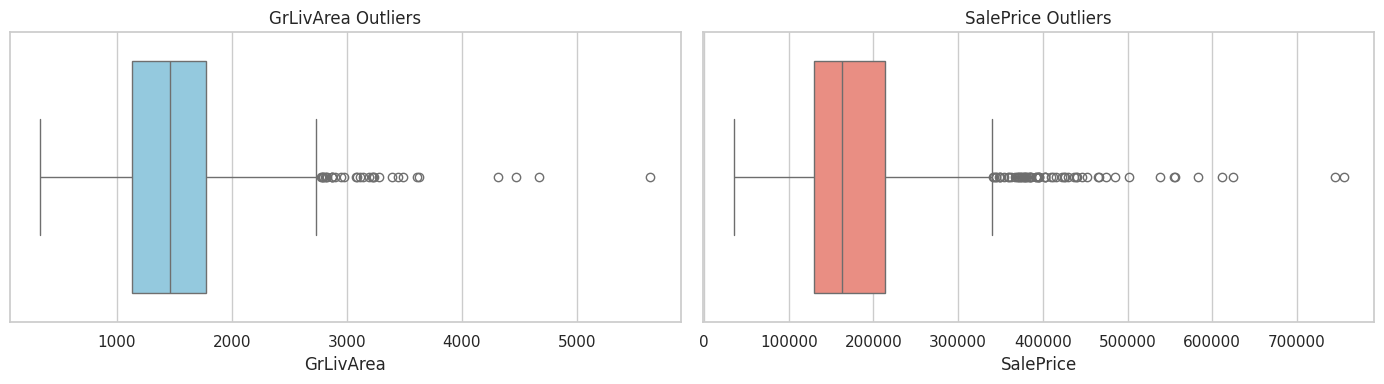

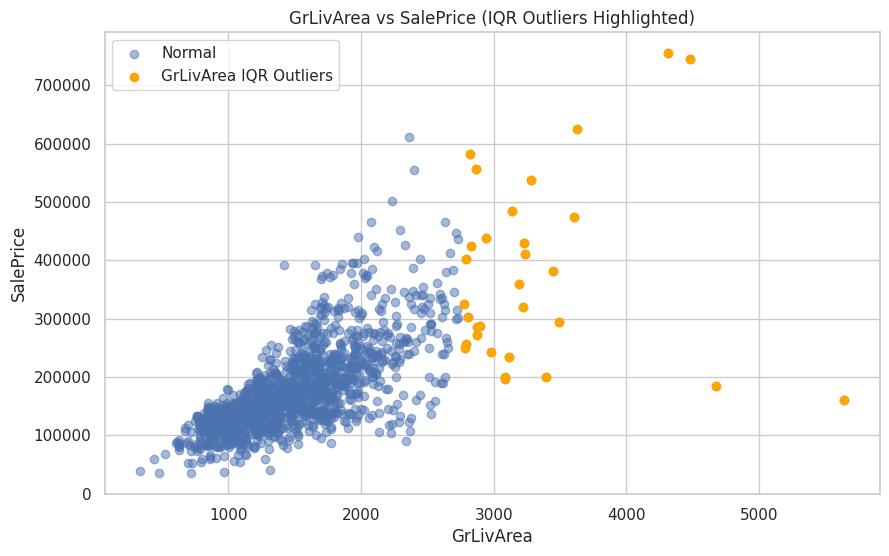


Original shape: (1460, 81) -> Cleaned shape: (1458, 81)


In [19]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[z.abs() > threshold]

for col in ["GrLivArea", "SalePrice"]:
    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col])
    overlap = a.index.intersection(b.index)
    print(f"--- {col} ---")
    print(f"IQR outliers: {len(a)} | Z-score outliers: {len(b)} | Overlap: {len(overlap)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df["GrLivArea"], ax=axes[0], color="skyblue")
axes[0].set_title("GrLivArea Outliers")
sns.boxplot(x=df["SalePrice"], ax=axes[1], color="salmon")
axes[1].set_title("SalePrice Outliers")
plt.tight_layout()
plt.show()

gr_outliers_idx = iqr_outliers(df["GrLivArea"]).index
plt.figure(figsize=(10, 6))
plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.5, label="Normal")
plt.scatter(df.loc[gr_outliers_idx, "GrLivArea"], df.loc[gr_outliers_idx, "SalePrice"],
            color="orange", label="GrLivArea IQR Outliers")
plt.title("GrLivArea vs SalePrice (IQR Outliers Highlighted)")
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.legend()
plt.show()

df_clean = df.drop(df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)].index).copy()
print(f"\nOriginal shape: {df.shape} -> Cleaned shape: {df_clean.shape}")

In [20]:
dup_count = df_clean.duplicated().sum()
print(f"Duplicate rows found: {dup_count}")
if dup_count > 0:
    df_clean = df_clean.drop_duplicates()
    print("New shape after dropping duplicates:", df_clean.shape)

cat_cols_obj = df_clean.select_dtypes(include=["object"]).columns
inconsistent = []
for col in cat_cols_obj:
    vals = df_clean[col].dropna().unique()
    cleaned_vals = set(str(v).strip().lower() for v in vals)
    if len(vals) != len(cleaned_vals):
        inconsistent.append(col)
print("Columns with casing/whitespace inconsistencies:", inconsistent)

for col in cat_cols_obj:
    df_clean[col] = df_clean[col].str.strip()

absent_cols = ["PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType"]
for col in absent_cols:
    df_clean[col] = df_clean[col].fillna("None")

df_clean["LotFrontage"] = df_clean.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)
df_clean["LotFrontage"] = df_clean["LotFrontage"].fillna(df_clean["LotFrontage"].median())

print("\nRemaining missing values in handled columns:")
print(df_clean[absent_cols + ["LotFrontage"]].isnull().sum())

impossible_years = df_clean[df_clean["YearBuilt"] > df_clean["YrSold"]]
negative_areas = df_clean[(df_clean["GrLivArea"] < 0) | (df_clean["LotArea"] < 0) | (df_clean["TotalBsmtSF"] < 0)]
print(f"\nRows where YearBuilt > YrSold: {len(impossible_years)}")
print(f"Rows with negative areas: {len(negative_areas)}")

Duplicate rows found: 0
Columns with casing/whitespace inconsistencies: []

Remaining missing values in handled columns:
PoolQC         0
Alley          0
Fence          0
FireplaceQu    0
GarageType     0
LotFrontage    0
dtype: int64

Rows where YearBuilt > YrSold: 0
Rows with negative areas: 0


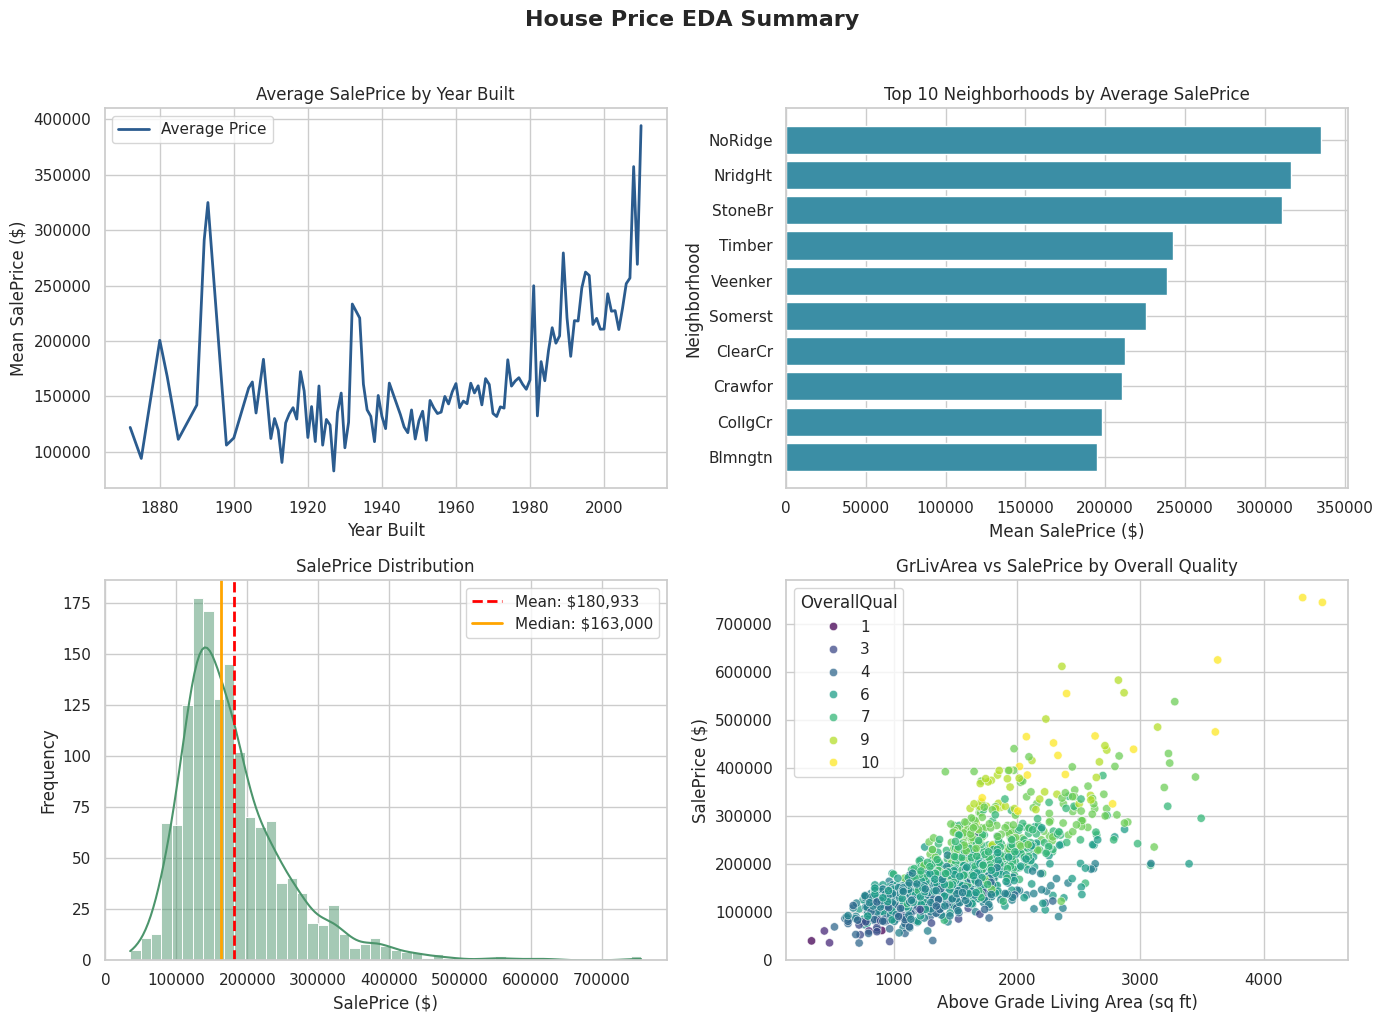

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
palette = sns.color_palette("viridis", as_cmap=True)

yearly_price = df_clean.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(yearly_price.index, yearly_price.values, color="#2b5c8f", linewidth=2, label="Average Price")
axes[0, 0].set_title("Average SalePrice by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Mean SalePrice ($)")
axes[0, 0].legend()

top10_nbhd = df_clean.groupby("Neighborhood")["SalePrice"].mean().sort_values(ascending=True).tail(10)
axes[0, 1].barh(top10_nbhd.index, top10_nbhd.values, color="#3b8ea5")
axes[0, 1].set_title("Top 10 Neighborhoods by Average SalePrice")
axes[0, 1].set_xlabel("Mean SalePrice ($)")
axes[0, 1].set_ylabel("Neighborhood")

sns.histplot(df_clean["SalePrice"], kde=True, ax=axes[1, 0], color="#4c956c")
mean_p = df_clean["SalePrice"].mean()
median_p = df_clean["SalePrice"].median()
axes[1, 0].axvline(mean_p, color="red", linestyle="--", linewidth=2, label=f"Mean: ${mean_p:,.0f}")
axes[1, 0].axvline(median_p, color="orange", linestyle="-", linewidth=2, label=f"Median: ${median_p:,.0f}")
axes[1, 0].set_title("SalePrice Distribution")
axes[1, 0].set_xlabel("SalePrice ($)")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()

sns.scatterplot(
    data=df_clean,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    alpha=0.75,
    ax=axes[1, 1]
)
axes[1, 1].set_title("GrLivArea vs SalePrice by Overall Quality")
axes[1, 1].set_xlabel("Above Grade Living Area (sq ft)")
axes[1, 1].set_ylabel("SalePrice ($)")

fig.suptitle("House Price EDA Summary", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()